# 04 — Classifier experiment: word and character patterns

The goal is to improve classifier performance before connecting it to the agent. This is a candidate experiment, not a claim of improvement. The existing text baseline uses words and phrases; this candidate also reads character sequences, which may capture spelling variations and unusual wording. Whether these help unfamiliar fraud groups must be measured.

**Keep the ongoing 03 run separate:** use a new notebook kernel, leave shared source files unchanged, and train this experiment after 03 or when sufficient CPU and memory are available. No training starts by default. Set `TRAIN_MODELS = ['logreg_word_char']` to train this candidate only. Completed matching results are reused; an interrupted partial candidate currently restarts from the beginning.

The comparison reuses notebook 02's two completed baselines and exact saved outer folds. Vocabulary learning happens inside each fit. The reserved test set is never read. Exact historical inner assignments and a training-time source/package manifest were not saved by 02; baseline folds and prediction metrics are verified here, but historical provenance cannot be fully reconstructed.

**Predeclared candidate:** word TF-IDF (1–2 word phrases, up to 30,000 terms) plus character-within-word TF-IDF (3–5 characters, up to 50,000 terms). Word and character block weights are 1.0 and 0.5. Class-balanced logistic regression tries C = 0.1, 0.3 and 1.0, using the same 3-fold inner grouped procedure and seed rule as 02. Character features change the representation; the classifier algorithm stays fixed. These choices are fixed before scoring outer folds.

Primary outcome: mean outer-fold PR-AUC. Also compare fraud recall, precision, F1 and performance when the top 5% of ads are reviewed. Examine paired uncertainty, not just the highest average. This text-only pipeline can later be exported as a single scoring tool for the LLM agent.

In [6]:
import hashlib
import importlib.metadata
import json
from pathlib import Path
import sys
import tempfile
from joblib import Memory
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/evaluation.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.features import build_inputs, logistic_pipeline, FEATURE_SETS
from src.evaluation import cross_validate, validate_folds, fold_signature, score_summary, summarise, paired_comparison
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

REPORT_DIR = ROOT / 'reports/classifier_word_char'
PREDICTION_DIR = ROOT / 'data/processed/classifier_word_char'
# Set to ['logreg_word_char'] when ready to train.
TRAIN_MODELS = ['logreg_word_char']
THREADS = 2
INNER_SPLITS = 3
SEED = 42
C_GRID = {'model__C': [0.1, 0.3, 1.0]}
BASELINES = {'logreg_text_30k': 'logreg_tf_idf_only', 'logreg_a2_30k': 'logreg_a2'}
CANDIDATES = ['logreg_word_char']
NAMES = {'logreg_text_30k': '02: text-only logistic (30k)',
         'logreg_a2_30k': '02: A2 logistic (30k)',
         'logreg_word_char': '04: word + character logistic'}

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

print('Training enabled for:', TRAIN_MODELS or 'none — load saved results only')

Training enabled for: ['logreg_word_char']


## 1. Recover and validate notebook 02's exact outer folds

Read only training data. Match saved job IDs and group IDs, check disjoint groups, and verify every fold signature against the baseline score tables. Fail rather than silently create replacement splits.

In [7]:
train_path = ROOT / 'data/processed/d1_train.csv'
assignment_path = ROOT / 'data/processed/model_cv_assignments.csv'
train = pd.read_csv(train_path)
assert train.job_id.is_unique
X = build_inputs(train)
y, groups = train.fraudulent.to_numpy(), train.group_id.to_numpy()
assignments = pd.read_csv(assignment_path)
positions = pd.Series(np.arange(len(train)), index=train.job_id)
folds = []
for (repeat, fold), rows in assignments.groupby(['repeat', 'fold'], sort=True):
    if not rows.job_id.is_unique or not rows.job_id.isin(positions.index).all():
        raise ValueError('Invalid job IDs in the saved assignments.')
    val = np.sort(positions.loc[rows.job_id].to_numpy())
    saved_groups = rows.set_index('job_id').group_id
    if not np.array_equal(saved_groups.loc[train.iloc[val].job_id].to_numpy(), groups[val]):
        raise ValueError('Group IDs differ from notebook 02.')
    fit = np.setdiff1d(np.arange(len(train)), val)
    folds.append((int(repeat), int(fold), fit, val))
folds = validate_folds(folds, y, groups)
expected = {(r, f): fold_signature(y, groups, fit, val) for r, f, fit, val in folds}

def validate_scores(scores):
    if scores.duplicated(['repeat', 'fold']).any():
        raise ValueError('Duplicate score rows.')
    actual = {(int(s.repeat), int(s.fold)): s.fold_signature for s in scores.itertuples()}
    if actual != expected:
        raise ValueError('Scores do not match the exact notebook 02 folds and current training rows.')

RESULTS = {}
for key, stem in BASELINES.items():
    scores = pd.read_csv(ROOT / f'reports/tables/model_{stem}_fold_scores.csv')
    validate_scores(scores)
    predictions = pd.read_csv(ROOT / f'data/processed/model_{stem}_oof.csv')
    if predictions.duplicated(['repeat', 'job_id']).any() or len(predictions) != len(train) * len({r for r, *_ in folds}):
        raise ValueError('Baseline predictions are incomplete or duplicated.')
    # Recompute each score from saved probabilities and saved thresholds; no training.
    for r, f, fit, val in folds:
        batch = predictions[predictions.repeat == r].set_index('job_id')
        p = batch.loc[train.iloc[val].job_id, 'probability'].to_numpy()
        row = scores[(scores.repeat == r) & (scores.fold == f)].iloc[0]
        measured = score_summary(y[val], p, threshold=row.threshold)
        for metric in ['pr_auc', 'precision', 'recall', 'f1']:
            if not np.isclose(measured[metric], row[metric]):
                raise ValueError(f'{key}: saved {metric} does not match its predictions.')
    RESULTS[key] = scores
print(f'Validated {len(folds)} saved outer folds on {len(train):,} ads. Reused both 02 baselines.')
display(pd.DataFrame({NAMES[k]: summarise(v, k) for k, v in RESULTS.items()}).T.round(3))

Validated 25 saved outer folds on 14,439 ads. Reused both 02 baselines.


,pr_auc,roc_auc,precision,recall,f1,share_flagged,false_positive_rate,precision_at_budget,recall_at_budget,precision_top5pct,recall_top5pct,pr_auc_sd
02: text-only logistic (30k),0.601,0.919,0.624,0.516,0.550,0.043,0.019,0.546,0.568,0.546,0.568,0.085
02: A2 logistic (30k),0.605,0.932,0.611,0.535,0.566,0.043,0.018,0.559,0.581,0.559,0.581,0.094


## 2. Train the candidate only when enabled

Training progress appears below this cell. Saved results have fingerprints for the data, outer folds, source files, baseline inputs, environment and candidate settings. A mismatch stops reuse rather than silently mixing experiments. Restart the kernel after changes to imported code. Partial checkpoints are saved for inspection but currently do not support fold-level resume.

In [8]:
def candidate_spec(key, memory=None):
    if key != 'logreg_word_char':
        raise ValueError(key)
    features = ColumnTransformer([
        ('word', TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5,
            max_features=30000, sublinear_tf=True, stop_words='english', dtype=np.float32), 'text_clean'),
        ('character', TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=5,
            max_features=50000, sublinear_tf=True, dtype=np.float32), 'text_clean'),
    ], transformer_weights={'word': 1.0, 'character': 0.5}, sparse_threshold=1.0)
    pipe = Pipeline([
        ('features', features),
        ('model', LogisticRegression(solver='liblinear', class_weight='balanced',
            random_state=SEED, max_iter=2000)),
    ], memory=memory)
    return pipe, C_GRID

if INNER_SPLITS != 3 or SEED != 42:
    raise ValueError('Reusing notebook 02 baselines requires INNER_SPLITS=3 and SEED=42.')
if set(TRAIN_MODELS) - set(CANDIDATES):
    raise ValueError('TRAIN_MODELS must contain only keys from CANDIDATES.')
context = {
    'training_sha256': sha(train_path), 'assignments_sha256': sha(assignment_path),
    'outer_signatures': {f'{r}:{f}': value for (r, f), value in expected.items()},
    'source_sha256': {name: sha(ROOT / 'src' / name) for name in ['features.py', 'evaluation.py', 'model_comparison.py']},
    'baseline_sha256': {str(path.relative_to(ROOT)): sha(path) for stem in BASELINES.values()
                       for path in [ROOT / f'reports/tables/model_{stem}_fold_scores.csv',
                                    ROOT / f'data/processed/model_{stem}_oof.csv']},
    'versions': {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn']},
    'seed': SEED, 'inner_splits': INNER_SPLITS, 'review_share': 0.05,
    'threshold': 'inner OOF maximum F1',
    'baseline_provenance': 'Imported from notebook 02; original source/package manifest unavailable. Outer folds and prediction metrics verified.'
}
for key in CANDIDATES:
    if key not in TRAIN_MODELS and not (REPORT_DIR / f'{key}_complete.json').exists():
        print(f'Pending: {key}. Add its key to TRAIN_MODELS to train it.')
        continue
    pipe, grid = candidate_spec(key)
    manifest = {**context, 'model': key, 'grid': grid, 'estimator': repr(pipe), 'threads': THREADS}
    plan_path = REPORT_DIR / f'{key}_plan.json'
    complete_path = REPORT_DIR / f'{key}_complete.json'
    score_path = REPORT_DIR / f'{key}_fold_scores.csv'
    if plan_path.exists() and json.loads(plan_path.read_text()) != manifest:
        raise ValueError(f'{key}: cached experiment differs. Choose a new REPORT_DIR and PREDICTION_DIR.')
    if complete_path.exists():
        completion = json.loads(complete_path.read_text())
        if not plan_path.exists() or sha(score_path) != completion['scores_sha256']:
            raise ValueError(f'{key}: incomplete or changed cached results.')
        scores = pd.read_csv(score_path)
        validate_scores(scores)
        RESULTS[key] = scores
        print(f'Reused completed {key}')
        continue
    if key not in TRAIN_MODELS:
        print(f'Pending: {key}. Add its key to TRAIN_MODELS to train it.')
        continue
    REPORT_DIR.mkdir(parents=True, exist_ok=True)
    PREDICTION_DIR.mkdir(parents=True, exist_ok=True)
    plan_path.write_text(json.dumps(manifest, indent=2))
    assignments.to_csv(REPORT_DIR / 'outer_assignments.csv', index=False)
    print(f'\nTraining {NAMES[key]}', flush=True)
    checkpoints, predictions = [], []
    with tempfile.TemporaryDirectory(prefix='bt4012_revised_') as cache:
        memory = Memory(cache, verbose=0)
        pipe, grid = candidate_spec(key, memory)
        def progress(row, val, probabilities):
            checkpoints.append({**row, 'selected_params': json.dumps(row['selected_params'], sort_keys=True)})
            pd.DataFrame(checkpoints).to_csv(score_path, index=False)
            predictions.append(pd.DataFrame({'repeat': row['repeat'], 'fold': row['fold'],
                'job_id': train.iloc[val].job_id.to_numpy(), 'probability': probabilities,
                'threshold': row['threshold']}))
            pd.concat(predictions, ignore_index=True).to_csv(PREDICTION_DIR / f'{key}_predictions.csv', index=False)
            memory.clear(warn=False)
        with threadpool_limits(limits=THREADS):
            scores, _ = cross_validate(lambda: pipe, X, y, groups, folds=folds,
                param_grid=grid, inner_splits=INNER_SPLITS, seed=SEED, on_fold=progress)
        candidates = scores.attrs['inner_candidates'].copy()
        candidates['params'] = candidates.params.map(lambda v: json.dumps(v, sort_keys=True))
        candidates.to_csv(REPORT_DIR / f'{key}_inner_settings.csv', index=False)
    validate_scores(scores)
    complete_path.write_text(json.dumps({'model': key, 'folds': len(scores), 'scores_sha256': sha(score_path)}, indent=2))
    RESULTS[key] = scores


Training 04: word + character logistic
Repeat 1, fold 1: PR-AUC 0.644, cutoff 0.571, settings {'model__C': 1.0}
Repeat 1, fold 2: PR-AUC 0.676, cutoff 0.541, settings {'model__C': 1.0}
Repeat 1, fold 3: PR-AUC 0.550, cutoff 0.615, settings {'model__C': 1.0}
Repeat 1, fold 4: PR-AUC 0.659, cutoff 0.636, settings {'model__C': 1.0}
Repeat 1, fold 5: PR-AUC 0.499, cutoff 0.574, settings {'model__C': 1.0}
Repeat 2, fold 1: PR-AUC 0.492, cutoff 0.538, settings {'model__C': 1.0}
Repeat 2, fold 2: PR-AUC 0.555, cutoff 0.610, settings {'model__C': 1.0}
Repeat 2, fold 3: PR-AUC 0.794, cutoff 0.601, settings {'model__C': 1.0}
Repeat 2, fold 4: PR-AUC 0.583, cutoff 0.576, settings {'model__C': 1.0}
Repeat 2, fold 5: PR-AUC 0.633, cutoff 0.559, settings {'model__C': 1.0}
Repeat 3, fold 1: PR-AUC 0.476, cutoff 0.506, settings {'model__C': 1.0}
Repeat 3, fold 2: PR-AUC 0.721, cutoff 0.534, settings {'model__C': 1.0}
Repeat 3, fold 3: PR-AUC 0.651, cutoff 0.536, settings {'model__C': 1.0}
Repeat 3, f

## 3. Compare completed results without fitting

All numbers below are means of the same outer-fold metrics, including the imported 02 baselines. Pending candidates are explicitly listed. Precision and recall use training-chosen cutoffs; the top-5% columns use a separate fixed review-budget policy. PR-AUC is ranking performance, not accuracy.

Comparison status: COMPLETE


,pr_auc,precision,recall,f1,precision_top5pct,recall_top5pct
04: word + character logistic,0.609,0.624,0.516,0.547,0.550,0.571
02: A2 logistic (30k),0.605,0.611,0.535,0.566,0.559,0.581
02: text-only logistic (30k),0.601,0.624,0.516,0.550,0.546,0.568


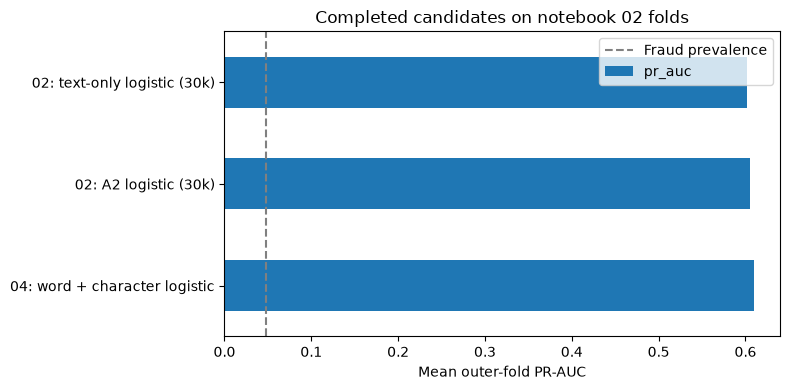

In [9]:
missing = [key for key in CANDIDATES if key not in RESULTS]
print('Comparison status:', 'COMPLETE' if not missing else f'PARTIAL — pending {missing}')
summary = pd.DataFrame({NAMES[k]: summarise(v, k) for k, v in RESULTS.items()}).T
summary = summary.sort_values('pr_auc', ascending=False)
display(summary[['pr_auc', 'precision', 'recall', 'f1', 'precision_top5pct', 'recall_top5pct']].round(3))
ax = summary.pr_auc.plot.barh(figsize=(8, 4), xlabel='Mean outer-fold PR-AUC', title='Completed candidates on notebook 02 folds')
ax.axvline(y.mean(), color='grey', linestyle='--', label='Fraud prevalence')
ax.legend()
plt.tight_layout()
plt.show()
REPORT_DIR.mkdir(parents=True, exist_ok=True)
summary.to_csv(REPORT_DIR / 'comparison_summary.csv')

## 4. Is an improvement supported?

Compare the candidate with both imported baselines using the same outer folds. The approximate corrected 95% intervals account for overlapping training sets; they are exploratory, not adjusted for repeated experimentation. An interval crossing zero does not establish a ranking improvement. Avoid changing settings repeatedly in response to these outer results. The final reserved test set remains untouched, and this notebook does not export a final fitted production model.

In [10]:
comparisons = []
for key in RESULTS:
    if key in BASELINES:
        continue
    for reference in BASELINES:
        difference = paired_comparison(RESULTS[key], RESULTS[reference], metric='pr_auc')
        comparisons.append({'candidate': NAMES[key], 'reference': NAMES[reference], **difference})
paired = pd.DataFrame(comparisons, columns=['candidate', 'reference', 'mean_diff', 'se', 'low', 'high', 'share_folds_a_better'])
if paired.empty:
    print('Candidate has not completed. Set TRAIN_MODELS in the setup cell when ready.')
else:
    display(paired.round(3))
paired.to_csv(REPORT_DIR / 'paired_differences.csv', index=False)
print('The reserved test set has not been opened.')

,candidate,reference,mean_diff,se,low,high,share_folds_a_better
0,04: word + character logistic,02: text-only logistic (30k),0.008,0.004,-0.00,0.016,0.80
1,04: word + character logistic,02: A2 logistic (30k),0.004,0.047,-0.09,0.099,0.56


The reserved test set has not been opened.
